In [14]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt 
import matplotlib.dates as mdates 

import datetime

plt.style.use("fivethirtyeight")

pd.set_option('display.max_rows', None)
pd.set_option('display.max_columns', None)

In [16]:

DB_FILE_PATH = "../db/harvest_main_log_df.csv"

In [17]:
main_df = pd.read_csv(DB_FILE_PATH)

In [18]:
main_df.Total = 0 
float_col_names = [col for col in main_df.columns if col not in ["Fertilisers", "Date"]]
print(float_col_names)
main_df[float_col_names] = main_df[float_col_names].apply(pd.to_numeric, errors = 'coerce')
main_df.Total = main_df[float_col_names].sum(axis= 1)

['Hibiscus_F', 'Kolkata_Pan_L', 'Mogai_Pan_L', 'Tulsi_Rama_L', 'Aloe_Vera_L', 'Tulsi_Sabja_L', 'Parijatak_L', 'Lemon_Grass_L', 'Tulsi_Kapoor_L', 'Tulsi_Krishna_L', 'Pudina_L', 'Brahmi_L', 'Nirgundi_L', 'Pippali_L', 'Adulsa_L', 'Mogra_F', 'Tulsi_Sabja_F', 'Neem_L', 'Tulsi_sabja_L', 'Rose_F', 'Fertiliser', 'Total', 'Double_Tagar_F', 'Curry_L', 'Tulsi_Krishna_F']


In [19]:
def plot_harvest(colname, total):
    try :  
        curr_df = main_df.copy() 
        # curr_df = curr_main_df[colname]

        _, ax = plt.subplots(figsize = (20, 10))
        curr_df.Date = pd.to_datetime(curr_df.Date)
        plt.plot(curr_df.Date, curr_df[colname], color='#666', linestyle= "-", linewidth=2, label='Trend')

        if colname != "Total" and total : 
            plt.plot(curr_df.Date, curr_df["Total"], color = '#888', linestyle = 'dashed', linewidth = 1, )

        # 2. The Dots (shows exact daily counts)
        processed_df = curr_df[curr_df[colname] > 0]
        plt.scatter(processed_df.Date, processed_df[colname], color='#333', zorder=5, label='Daily Count')

            # Calculates a 14-day rolling average
        # 'min_periods=1' ensures it still draws a line even if a few days are missing
        processed_df = curr_df.copy() 
        processed_df['Rolling_Avg'] = processed_df[colname].rolling(window=7, min_periods=1, center=True).mean()

        # Plot line
        plt.plot(processed_df['Date'], processed_df['Rolling_Avg'], color='darkcyan', linewidth=2)

        ax = plt.gca() # Get current axis

        # Set ticks to happen at the start of every Month
        ax.xaxis.set_major_locator(mdates.MonthLocator())

        # Format the label to show short Month name and Year (e.g., "Jun 2026")
        ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
        # plt.gcf().autofmt_xdate()

        daily_avg = round(curr_df[colname].mean(), 2)
        daily_perc_usage = round(len(curr_df[curr_df[colname] > 0 ]) * 100 / len(curr_df), 2) 
        total_harvest = curr_df[colname].sum(axis = 0)

        plt.title(f'{colname} | Total : {total_harvest} | Avg : {daily_avg} | Daily_Perc_Usage : {daily_perc_usage} %', fontsize=30, fontweight='bold', color = "#444")
        plt.xlabel('Month')
        plt.ylabel(colname)
        plt.grid(True, linestyle='--', alpha=0.5)

        plt.show() 
    except KeyError as k:
        plt.close("all")

        print(k)
        print(main_df.columns)
    except ValueError as v: 
        plt.close("all")
        print(v)
    except Exception as e: 
        plt.close("all")
        print(e)



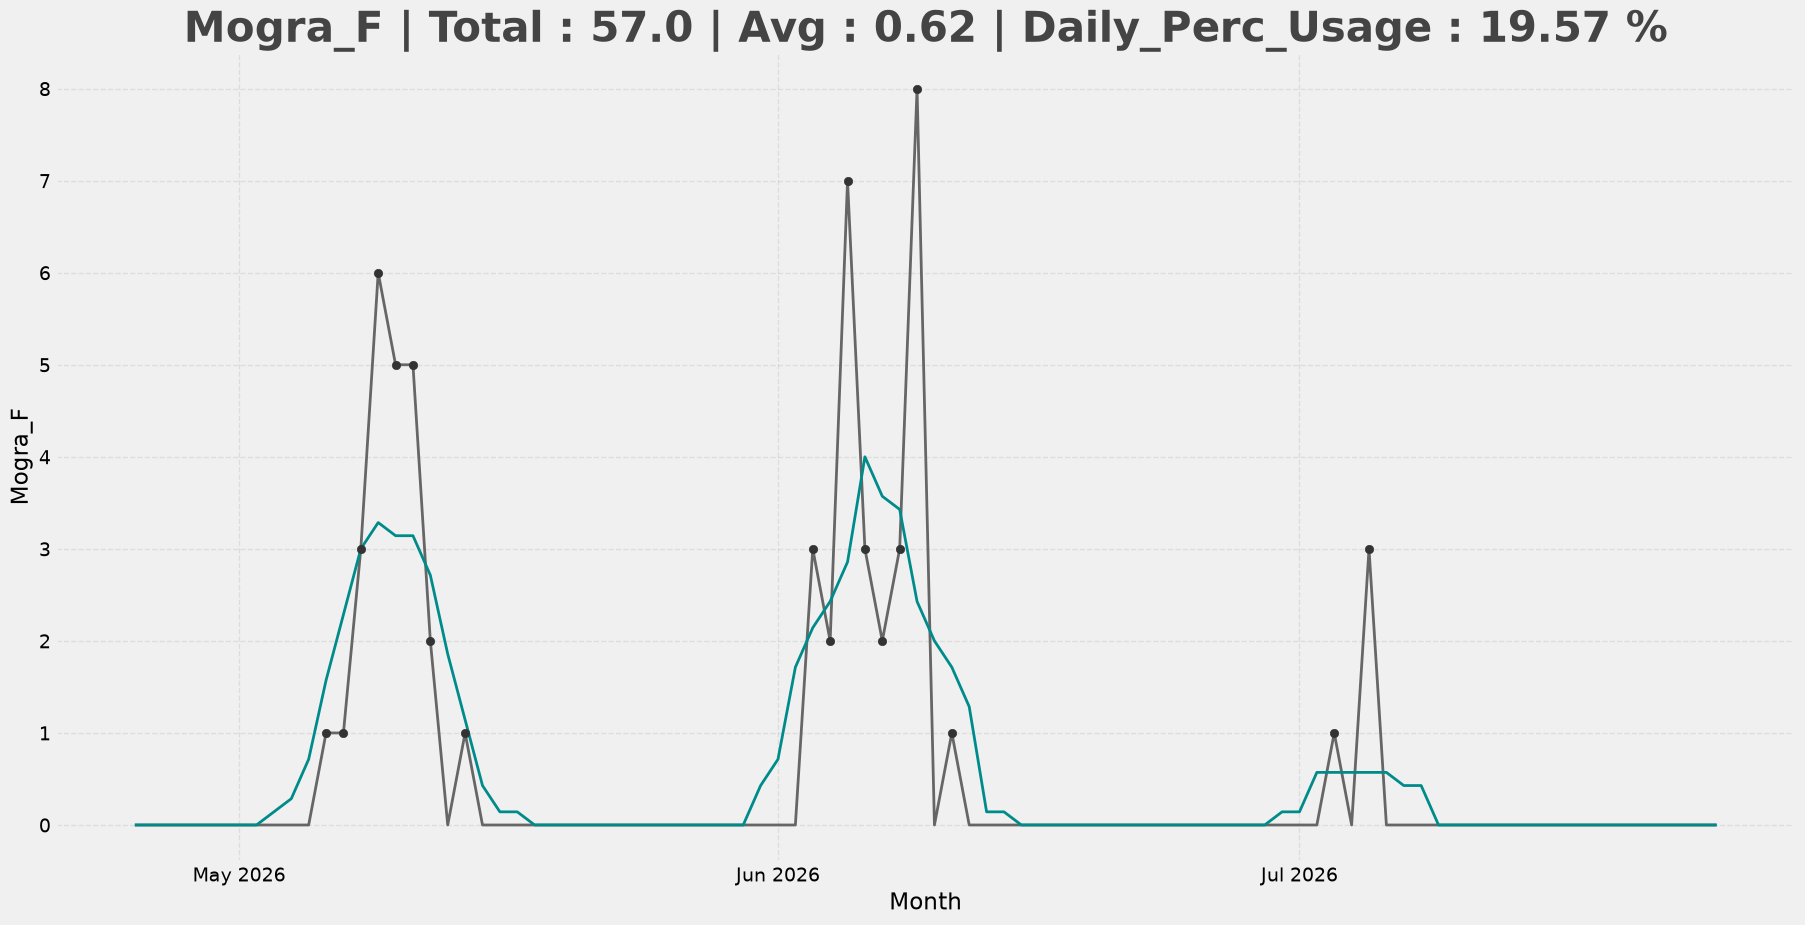

In [25]:
colname = "Mogra_F"
# total = False 
fertiliser_info = False 
plot_harvest(colname, total = False ) 

# Plot by harvest Categories 

In [183]:
def plot_by_Cat(cat, show_total, show_cat, show_sub_cat): 
    # cat = "Tulsi_Vrundavan"
    # show_total = True 
    try:
        main_df.Date = pd.to_datetime(main_df.Date)

        filtered_col = []

        if cat == "all": 
            for c in harvest_category_map: 
                for col in harvest_category_map[c]: 
                    if col in main_df.columns and col not in filtered_col: 
                        filtered_col.append(col)

            
            # print(filtered_col)
        else: 
            for col in harvest_category_map[cat]: 
                if col in main_df.columns:  filtered_col.append(col)

        cat_df = main_df[filtered_col]
        cat_df["Total_x"] = cat_df.sum(axis = 1)
        
        _, ax = plt.subplots(figsize = (20, 10))
        if show_cat: 
            plt.plot(main_df.Date, cat_df["Total_x"], label = cat, linestyle ="dashed", color = "#1e552f", linewidth = 1.8 )
        if show_total :
            plt.plot(main_df.Date, main_df.Total, linestyle = "dashed", color = "#333", label = "Total")

        if show_sub_cat: 
            for col in filtered_col:
                plt.plot(main_df.Date, main_df[col], label = col, alpha = 0.6)

        ax = plt.gca() # Get current axis
        
        # Set ticks to happen at the start of every Month
        ax.xaxis.set_major_locator(mdates.MonthLocator())

        # Format the label to show short Month name and Year (e.g., "Jun 2026")
        ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
        # plt.gcf().autofmt_xdate()

        _all_sum = cat_df["Total_x"].sum(axis = 0)
        _all_avg = round(_all_sum/ cat_df.shape[0], 2) 
        _daily_perc_usage = round(len(cat_df[cat_df["Total_x"] > 0]) * 100 / len(cat_df), 2) 
        plt.title(f"{cat} : {_all_sum} | Avg : {_all_avg} | Daily Perc Usage : {_daily_perc_usage} %", fontsize = 30, fontweight = "bold")


        plt.legend(loc = 'upper left')
        plt.xlabel("Month")
        plt.ylabel(cat)
        plt.show()
    except Exception as e: print(e)

In [188]:
harvest_category_map = {
    "all" : [],
    "Tulsi_Vrundavan" : ["Tulsi_Krishna_L", "Tulsi_Rama_L", "Tulsi_Sabja_L", "Tulsi_Sabja_F", "Tulsi_Kapoor_L"],
    "Jasmine" : ["Mogra_F", "Jai_F", "Jui_F", "Kunda_F"],
    "Daily_Pooja_Flowers" : ["Hibiscus_F", "Gokarna_F", "Double_Tagar_F"], 
    "Daily_Pooja_Leaves" : ["Tulsi_Krishna_L", "Tulsi_Rama_L", "Tulsi_Sabja_L", "Tulsi_Sabja_F", "Tulsi_Kapoor_L", "Bael_L"],
    "Fragrance_Flower" : ["Double_Tagar_F", "Sonchafa_F", "Bakul_F", "Mogra_F", "Jai_F", "Jui_F", "Parijatak_F", "Tulsi_Sabja_F", "Gandharaja_F", "Rose_F"],
    "Shiva_Pooja" : ["Rui_L", "Rui_F", "Bael_L", "Dhatura_F", "Dhatura_F2"],
    "Satvic_Flowers" : ["Mogra_F", "Jai_F", "Jui_F", "Kunda_F", "Gokarna_F", "Double_Tagar", "Bakul_F", "Parijatak_F", "Gandharaja_F", "Rui_F", "Dhatura_F"]
}

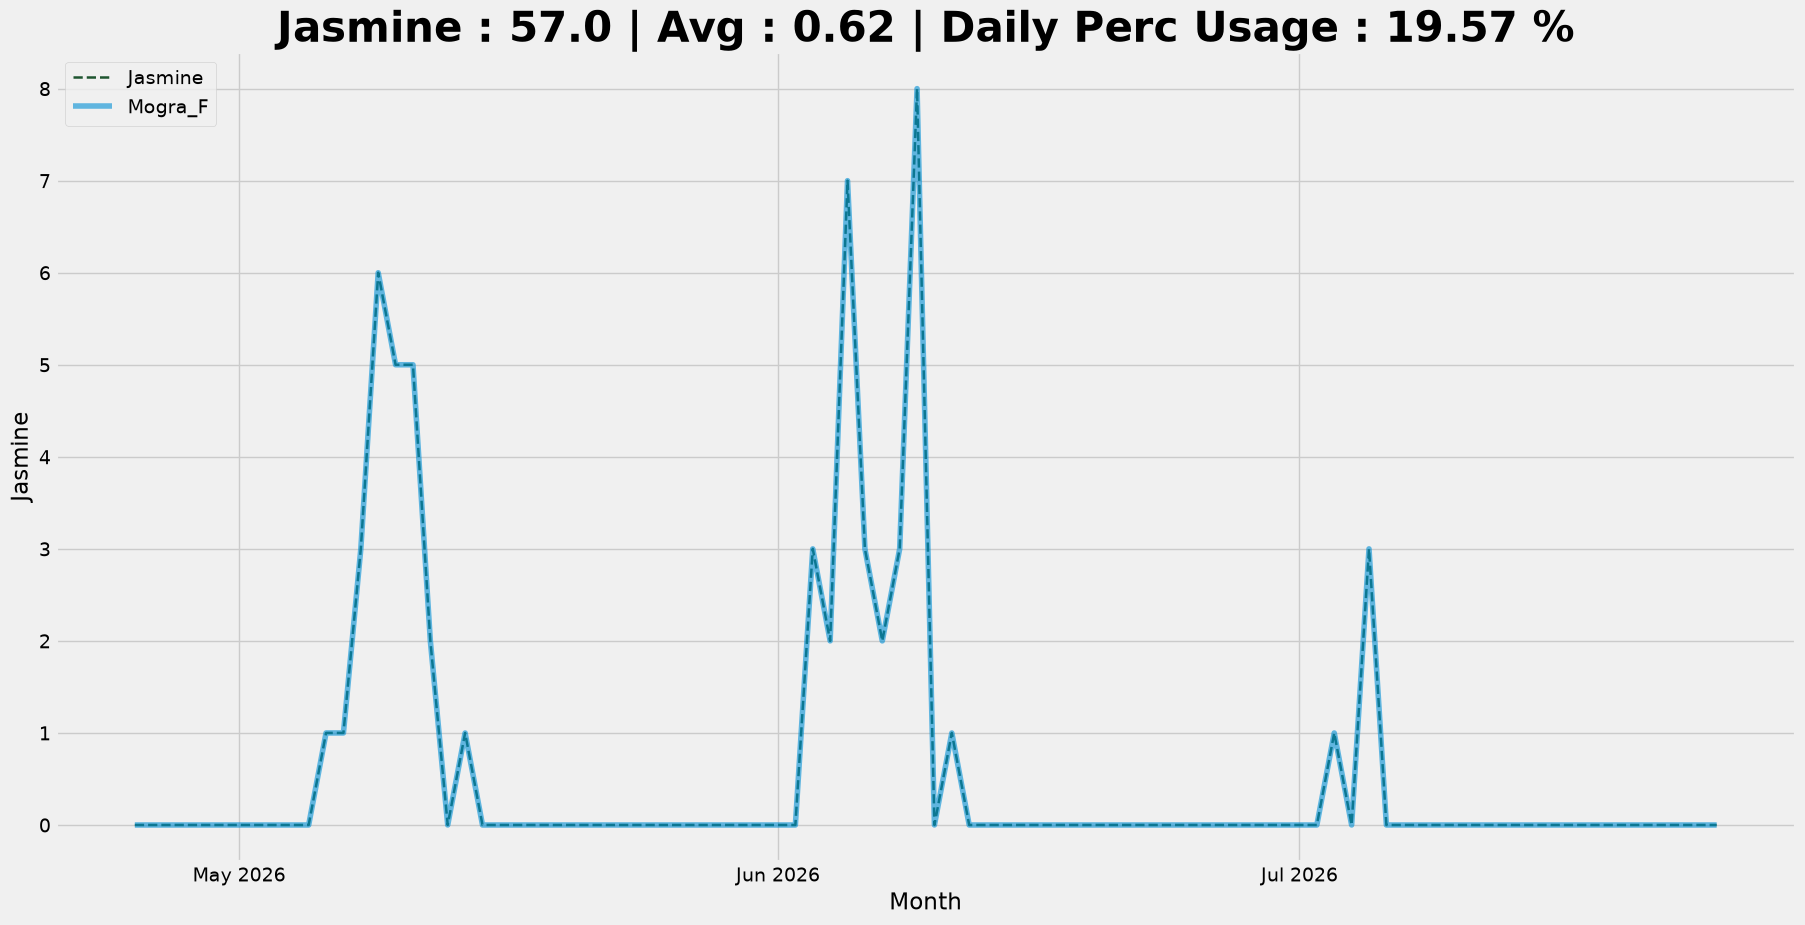

In [191]:
plot_by_Cat("Jasmine", show_total = False, show_cat = True, show_sub_cat = True)